In [1]:
!pip install torchmetrics -q

In [2]:
import torch
import torch.nn as nn
import torchmetrics
import torchvision
import torchvision.transforms.v2 as T
import matplotlib.pyplot as plt
import numpy as np

In [3]:
from sklearn.datasets import load_sample_images
sample_images = load_sample_images()['images']
sample_images =  np.stack(sample_images)
sample_images  = torch.FloatTensor(sample_images)
sample_images /=255

In [4]:
sample_images_permuted = sample_images.permute(0,3,1,2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

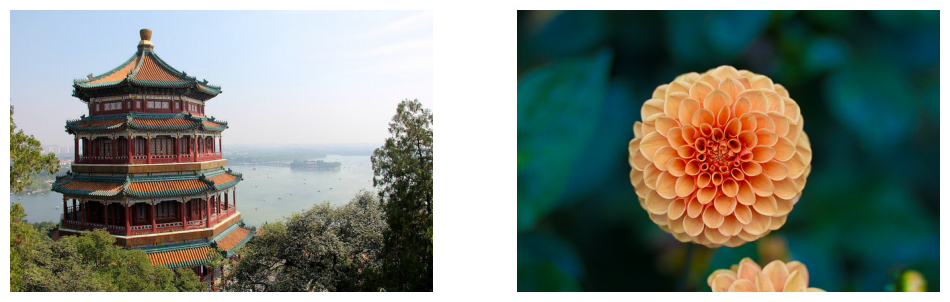

In [5]:
def plot_image(image_tensor):
  plt.imshow(image_tensor.permute(1,2,0))
  plt.axis('off')

plt.figure(figsize=(12,6))
for index, image_tensor in enumerate(sample_images_permuted):
  plt.subplot(1,2,index+1)
  plot_image(image_tensor)

In [6]:
from torchvision.models import list_models
list_models()

['alexnet',
 'convnext_base',
 'convnext_large',
 'convnext_small',
 'convnext_tiny',
 'deeplabv3_mobilenet_v3_large',
 'deeplabv3_resnet101',
 'deeplabv3_resnet50',
 'densenet121',
 'densenet161',
 'densenet169',
 'densenet201',
 'efficientnet_b0',
 'efficientnet_b1',
 'efficientnet_b2',
 'efficientnet_b3',
 'efficientnet_b4',
 'efficientnet_b5',
 'efficientnet_b6',
 'efficientnet_b7',
 'efficientnet_v2_l',
 'efficientnet_v2_m',
 'efficientnet_v2_s',
 'fasterrcnn_mobilenet_v3_large_320_fpn',
 'fasterrcnn_mobilenet_v3_large_fpn',
 'fasterrcnn_resnet50_fpn',
 'fasterrcnn_resnet50_fpn_v2',
 'fcn_resnet101',
 'fcn_resnet50',
 'fcos_resnet50_fpn',
 'googlenet',
 'inception_v3',
 'keypointrcnn_resnet50_fpn',
 'lraspp_mobilenet_v3_large',
 'maskrcnn_resnet50_fpn',
 'maskrcnn_resnet50_fpn_v2',
 'maxvit_t',
 'mc3_18',
 'mnasnet0_5',
 'mnasnet0_75',
 'mnasnet1_0',
 'mnasnet1_3',
 'mobilenet_v2',
 'mobilenet_v3_large',
 'mobilenet_v3_small',
 'mvit_v1_b',
 'mvit_v2_s',
 'quantized_googlenet',
 '

In [7]:
if torch.cuda.is_available():
  device ='cuda'
elif torch.mps.is_available():
  device = 'mps'
else:
  device = 'cpu'

In [8]:
device

'cuda'

In [9]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
model = torchvision.models.convnext_base(weights=weights).to(device)

In [10]:
model

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=128, out_features=512, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=512, out_features=128, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(

In [11]:
weights.meta

{'min_size': (32, 32),
 'categories': ['tench',
  'goldfish',
  'great white shark',
  'tiger shark',
  'hammerhead',
  'electric ray',
  'stingray',
  'cock',
  'hen',
  'ostrich',
  'brambling',
  'goldfinch',
  'house finch',
  'junco',
  'indigo bunting',
  'robin',
  'bulbul',
  'jay',
  'magpie',
  'chickadee',
  'water ouzel',
  'kite',
  'bald eagle',
  'vulture',
  'great grey owl',
  'European fire salamander',
  'common newt',
  'eft',
  'spotted salamander',
  'axolotl',
  'bullfrog',
  'tree frog',
  'tailed frog',
  'loggerhead',
  'leatherback turtle',
  'mud turtle',
  'terrapin',
  'box turtle',
  'banded gecko',
  'common iguana',
  'American chameleon',
  'whiptail',
  'agama',
  'frilled lizard',
  'alligator lizard',
  'Gila monster',
  'green lizard',
  'African chameleon',
  'Komodo dragon',
  'African crocodile',
  'American alligator',
  'triceratops',
  'thunder snake',
  'ringneck snake',
  'hognose snake',
  'green snake',
  'king snake',
  'garter snake',
 

In [12]:
len(weights.meta["categories"])

1000

In [13]:
transform = weights.transforms()
transform

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [14]:
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

In [15]:
transform

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [16]:
preprocessed_image = transform(sample_images_permuted).to(device)
preprocessed_image.shape

torch.Size([2, 3, 224, 224])

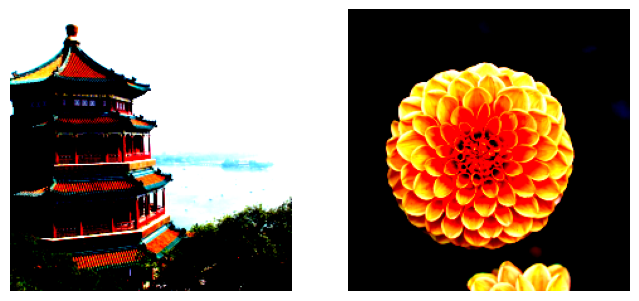

In [17]:
plt.figure(figsize=(8,4))
for index, image_tensor in enumerate(torch.Tensor.cpu(preprocessed_image)):
  plt.subplot(1,2,index+1)
  plot_image(image_tensor)

In [18]:
# with torch.inference_mode():
with torch.no_grad():
  y_logit = model(preprocessed_image)

y_probas = y_logit.softmax(dim=1)
y_probas

tensor([[1.6485e-04, 5.4289e-05, 6.2805e-05,  ..., 7.7442e-05, 1.0931e-04,
         3.8042e-05],
        [2.7500e-04, 9.2272e-04, 9.9854e-05,  ..., 9.1855e-04, 1.2467e-02,
         3.3965e-04]], device='cuda:0')

In [19]:
y_preds = y_logit.argmax(dim=1)
y_preds

tensor([698, 599], device='cuda:0')

In [20]:
class_names = weights.meta['categories']

In [21]:
[[class_names[cls_idx]]for cls_idx in y_preds ]

[['palace'], ['honeycomb']]

In [22]:
y_probas.topk(k=5,dim=1)

torch.return_types.topk(
values=tensor([[0.8844, 0.0249, 0.0029, 0.0019, 0.0018],
        [0.1144, 0.1051, 0.0513, 0.0344, 0.0297]], device='cuda:0'),
indices=tensor([[698, 663, 975, 832, 858],
        [599, 985, 947, 991, 883]], device='cuda:0'))

In [23]:
y_top5_values, y_top5_idx = y_probas.topk(k=5,dim=1)

In [24]:
y_top5_values

tensor([[0.8844, 0.0249, 0.0029, 0.0019, 0.0018],
        [0.1144, 0.1051, 0.0513, 0.0344, 0.0297]], device='cuda:0')

In [25]:
y_top5_idx

tensor([[698, 663, 975, 832, 858],
        [599, 985, 947, 991, 883]], device='cuda:0')

In [26]:
y_top5_preds = [[class_names[idx] for idx in img_idx]for img_idx in y_top5_idx]

In [27]:
y_top5_preds

[['palace', 'monastery', 'lakeside', 'stupa', 'tile roof'],
 ['honeycomb', 'daisy', 'mushroom', 'coral fungus', 'vase']]

Transfer Learning(parametr tuning)


In [28]:
transform = T.Compose(transforms = [
    T.ToTensor(),
    T.CenterCrop(size=500)]
)
flowers_to_display = torchvision.datasets.Flowers102(
    root='datasets',
    split='train',
    download=True,
    transform=transform
)
flowers_to_display

/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


Dataset Flowers102
    Number of datapoints: 1020
    Root location: datasets
    split=train
    StandardTransform
Transform: Compose(
                 ToTensor()
                 CenterCrop(size=(500, 500))
           )

In [29]:
class_names = torchvision.datasets.Flowers102.classes

In [30]:
class_names

['pink primrose',
 'hard-leaved pocket orchid',
 'canterbury bells',
 'sweet pea',
 'english marigold',
 'tiger lily',
 'moon orchid',
 'bird of paradise',
 'monkshood',
 'globe thistle',
 'snapdragon',
 "colt's foot",
 'king protea',
 'spear thistle',
 'yellow iris',
 'globe-flower',
 'purple coneflower',
 'peruvian lily',
 'balloon flower',
 'giant white arum lily',
 'fire lily',
 'pincushion flower',
 'fritillary',
 'red ginger',
 'grape hyacinth',
 'corn poppy',
 'prince of wales feathers',
 'stemless gentian',
 'artichoke',
 'sweet william',
 'carnation',
 'garden phlox',
 'love in the mist',
 'mexican aster',
 'alpine sea holly',
 'ruby-lipped cattleya',
 'cape flower',
 'great masterwort',
 'siam tulip',
 'lenten rose',
 'barbeton daisy',
 'daffodil',
 'sword lily',
 'poinsettia',
 'bolero deep blue',
 'wallflower',
 'marigold',
 'buttercup',
 'oxeye daisy',
 'common dandelion',
 'petunia',
 'wild pansy',
 'primula',
 'sunflower',
 'pelargonium',
 'bishop of llandaff',
 'gaura',

In [31]:
sample_flowers = sorted({y:img for img, y in flowers_to_display}.items())[:12]

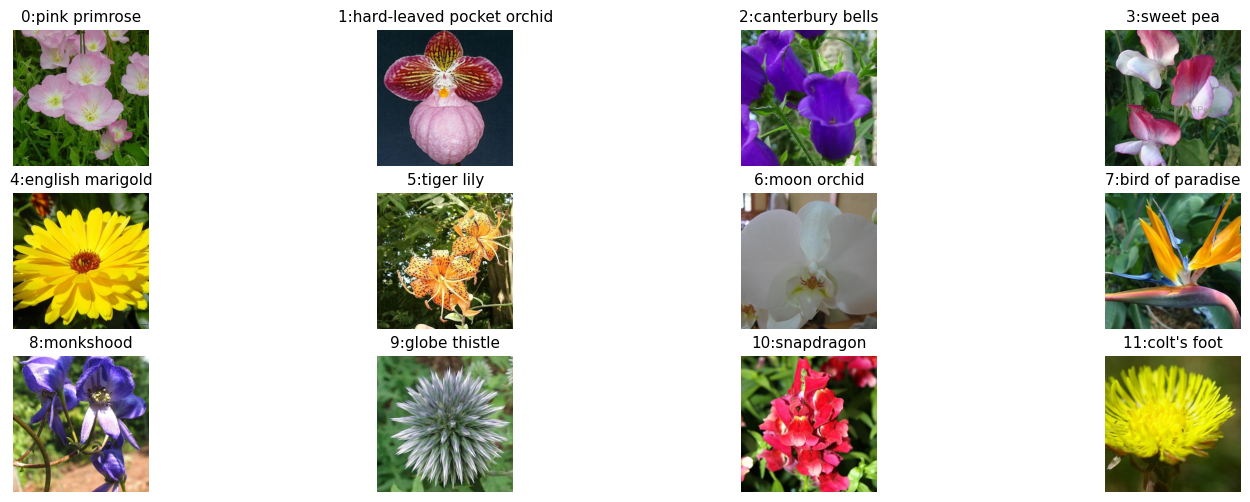

In [32]:
plt.figure(figsize=(18,6))
for class_id, image in sample_flowers:
  if class_id ==12:
    break
  plt.subplot(3,4,class_id+1)
  plot_image(image)
  plt.title(f"{class_id}:{class_names[class_id]}",fontsize=11)
plt.show()

In [33]:
flowers_to_display[0][0].shape

torch.Size([3, 500, 500])

In [34]:
model = torchvision.models.convnext_base(weights=weights).to(device)
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
transforms = weights.transforms()

In [35]:
from functools import partial

DefaultFlowers102 = partial(torchvision.datasets.Flowers102,
        root='datasets',
        download=True,
        transform=transforms)

train_set = DefaultFlowers102(
    split='train',
)
test_set = DefaultFlowers102(
    split='test',
)
valid_set = DefaultFlowers102(
    split='val',
)

In [36]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_set,batch_size=32,shuffle=True)
test_loader = DataLoader(test_set,batch_size=32)
valid_loader = DataLoader(valid_set,batch_size=32)

In [37]:
next(iter(train_loader))[0]

tensor([[[[-1.3302, -1.3302, -1.3987,  ..., -1.3473, -0.7137, -0.4739],
          [-0.8849, -0.4911, -1.1247,  ..., -1.3473, -0.7993, -0.4739],
          [-0.1657,  0.5707,  0.5022,  ..., -1.4158, -0.9020, -0.5082],
          ...,
          [ 0.7248,  0.2624,  0.5707,  ..., -1.4672, -1.4843, -1.4672],
          [ 1.3070,  0.7077,  0.5536,  ..., -1.4329, -1.4500, -1.4158],
          [ 1.1529,  1.1187,  0.7591,  ..., -1.4329, -1.4672, -1.4329]],

         [[-1.4755, -1.4755, -1.5280,  ..., -1.2479, -0.5826, -0.2850],
          [-0.9503, -0.5476, -1.2129,  ..., -1.2829, -0.6702, -0.3025],
          [-0.1625,  0.6078,  0.5378,  ..., -1.3529, -0.7927, -0.3550],
          ...,
          [ 0.5028,  0.0126,  0.2752,  ..., -1.5280, -1.5455, -1.5280],
          [ 1.0630,  0.4153,  0.2227,  ..., -1.5455, -1.5630, -1.5280],
          [ 0.8704,  0.7829,  0.3627,  ..., -1.5980, -1.6155, -1.5805]],

         [[-1.3861, -1.3687, -1.4384,  ..., -1.5779, -1.0201, -0.8284],
          [-0.8633, -0.4450, -

In [38]:
list(model.named_children())

[('features',
  Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=128, out_features=512, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=512, out_features=128, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
          (1): Permute()
          (2): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_featu

In [39]:
[name for name, child in model.named_children()]

['features', 'avgpool', 'classifier']

In [40]:
model.classifier[2]

Linear(in_features=1024, out_features=1000, bias=True)

In [41]:
len(class_names)

102

In [42]:
n_classes = len(class_names)
model.classifier[2] = nn.Linear(in_features=1024, out_features=102, bias=True).to(device)

In [43]:
model.classifier[2]

Linear(in_features=1024, out_features=102, bias=True)

In [44]:
for param in model.features.parameters():
  param.requires_grad = False

In [45]:
for param in model.classifier[2].parameters():
  param.requires_grad = True

In [46]:
from custom_utils import train, plot_history

In [47]:
n_epochs = 10
optimizer = torch.optim.AdamW(model.parameters())
criterion = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass", num_classes=n_classes).to(device)

history = train(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device = device,
    restore_best_parameters = False,
  )

Epoch: 1/10, Train Loss: 4.276, Train Metric: 0.136, Valid Metric: 0.579, Time: 34.68s
	Checkpoint, valid metric : 0.579
Epoch: 2/10, Train Loss: 2.998, Train Metric: 0.692, Valid Metric: 0.742, Time: 33.03s
	Checkpoint, valid metric : 0.742
Epoch: 3/10, Train Loss: 2.026, Train Metric: 0.851, Valid Metric: 0.827, Time: 31.58s
	Checkpoint, valid metric : 0.827
Epoch: 4/10, Train Loss: 1.371, Train Metric: 0.902, Valid Metric: 0.853, Time: 31.21s
	Checkpoint, valid metric : 0.853
Epoch: 5/10, Train Loss: 0.965, Train Metric: 0.938, Valid Metric: 0.855, Time: 32.08s
	Checkpoint, valid metric : 0.855
Epoch: 6/10, Train Loss: 0.655, Train Metric: 0.964, Valid Metric: 0.882, Time: 31.5s
	Checkpoint, valid metric : 0.882
Epoch: 7/10, Train Loss: 0.51, Train Metric: 0.979, Valid Metric: 0.885, Time: 31.49s
	Checkpoint, valid metric : 0.885
Epoch: 8/10, Train Loss: 0.389, Train Metric: 0.979, Valid Metric: 0.889, Time: 31.86s
	Checkpoint, valid metric : 0.889
Epoch: 9/10, Train Loss: 0.311, Tr

In [48]:
history = train(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device = device,
    restore_best_parameters = False,
  )

Epoch: 1/10, Train Loss: 0.211, Train Metric: 0.993, Valid Metric: 0.893, Time: 31.23s
	Checkpoint, valid metric : 0.893
Epoch: 2/10, Train Loss: 0.17, Train Metric: 0.996, Valid Metric: 0.893, Time: 30.92s
Epoch: 3/10, Train Loss: 0.151, Train Metric: 0.997, Valid Metric: 0.891, Time: 30.69s
Epoch: 4/10, Train Loss: 0.134, Train Metric: 0.996, Valid Metric: 0.9, Time: 36.65s
	Checkpoint, valid metric : 0.900
Epoch: 5/10, Train Loss: 0.103, Train Metric: 0.998, Valid Metric: 0.899, Time: 31.29s
Epoch: 6/10, Train Loss: 0.102, Train Metric: 0.999, Valid Metric: 0.901, Time: 36.55s
	Checkpoint, valid metric : 0.901
Epoch: 7/10, Train Loss: 0.092, Train Metric: 0.998, Valid Metric: 0.908, Time: 31.59s
	Checkpoint, valid metric : 0.908
Epoch: 8/10, Train Loss: 0.075, Train Metric: 1.0, Valid Metric: 0.901, Time: 31.46s
Epoch: 9/10, Train Loss: 0.073, Train Metric: 0.999, Valid Metric: 0.903, Time: 30.21s
Epoch: 10/10, Train Loss: 0.064, Train Metric: 0.999, Valid Metric: 0.903, Time: 31.08

In [49]:
for param in model.parameters():
    param.requires_grad = True

In [50]:
history = train(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    15,
    device = device,
    restore_best_parameters = True,
  )

Epoch: 1/15, Train Loss: 0.723, Train Metric: 0.794, Valid Metric: 0.767, Time: 83.28s
	Checkpoint, valid metric : 0.767
Epoch: 2/15, Train Loss: 0.357, Train Metric: 0.9, Valid Metric: 0.833, Time: 82.38s
	Checkpoint, valid metric : 0.833
Epoch: 3/15, Train Loss: 0.225, Train Metric: 0.938, Valid Metric: 0.841, Time: 78.63s
	Checkpoint, valid metric : 0.841
Epoch: 4/15, Train Loss: 0.265, Train Metric: 0.927, Valid Metric: 0.801, Time: 75.54s
Epoch: 5/15, Train Loss: 0.187, Train Metric: 0.948, Valid Metric: 0.783, Time: 75.49s
Epoch: 6/15, Train Loss: 0.155, Train Metric: 0.949, Valid Metric: 0.758, Time: 75.64s
Epoch: 7/15, Train Loss: 0.239, Train Metric: 0.931, Valid Metric: 0.773, Time: 75.52s
Epoch: 8/15, Train Loss: 0.142, Train Metric: 0.958, Valid Metric: 0.783, Time: 75.36s
Epoch: 9/15, Train Loss: 0.154, Train Metric: 0.959, Valid Metric: 0.794, Time: 75.41s
Epoch: 10/15, Train Loss: 0.19, Train Metric: 0.949, Valid Metric: 0.78, Time: 75.5s
Epoch: 11/15, Train Loss: 0.087,